# Практика: Метрики классификации и регрессии
### Датасет: Цены на автомобили 🚗

Нашел датасет по ценам на подержанные машины — там марка, год, пробег, двигатель, лошадиные силы и цена.  
Идея:
- **Регрессия** — предсказать точную цену автомобиля
- **Классификация** — предсказать дорогая машина или нет (выше медианы)


## Импорты и загрузка данных

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve,
    mean_squared_error, mean_absolute_error, r2_score
)

import warnings
warnings.filterwarnings('ignore')

In [30]:
df = pd.read_csv('car_prices.csv')
print("Размер датасета:", df.shape)
df.head(10)

Размер датасета: (2000, 7)


,brand,year,km_driven,engine_cc,horsepower,fuel_type,price_usd
0,Hyundai,2014,23185,1000,324,Petrol,37319
1,Honda,2011,174514,3200,349,Petrol,20051
2,Volkswagen,2013,133653,4000,268,Petrol,30055
3,Ford,2021,51717,2900,224,Diesel,45465
4,Hyundai,2015,2763,1300,401,Petrol,41251
5,Mazda,2011,55480,4900,430,Diesel,42400
6,Mercedes,2018,169831,3100,379,Petrol,57411
7,Hyundai,2023,207139,3500,211,Diesel,15375
8,Volkswagen,2008,118094,1900,349,Diesel,31885
9,Ford,2010,156379,2900,327,Diesel,20674


In [31]:
df.describe()

,year,km_driven,engine_cc,horsepower,price_usd
count,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000
mean,2013.987000,152996.998500,2981.05000,254.385000,29874.043500
std,5.530925,87160.566704,1160.58148,114.685636,15765.352428
min,2005.000000,215.000000,1000.00000,60.000000,2000.000000
25%,2009.000000,79103.000000,2000.00000,153.000000,17492.500000
50%,2014.000000,154346.000000,2900.00000,255.000000,29065.500000
75%,2019.000000,229377.500000,4000.00000,355.000000,40522.250000
max,2023.000000,299569.000000,5000.00000,449.000000,77154.000000


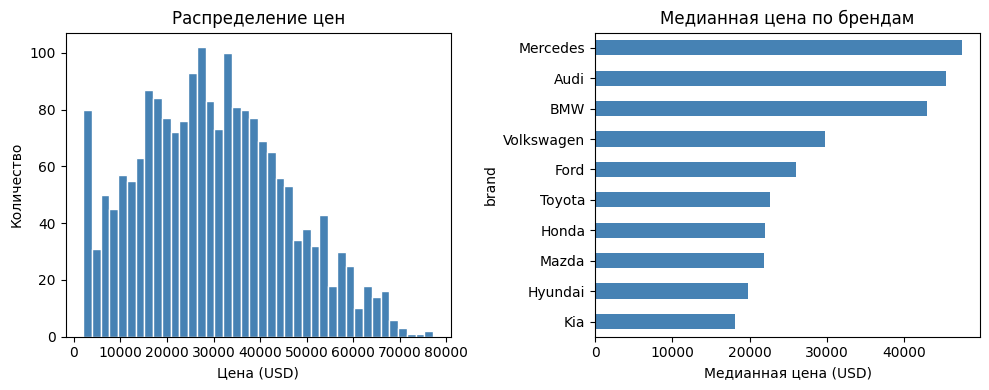

In [32]:
# смотрю распределение цен
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df['price_usd'], bins=40, color='steelblue', edgecolor='white')
plt.xlabel('Цена (USD)')
plt.ylabel('Количество')
plt.title('Распределение цен')

plt.subplot(1, 2, 2)
df.groupby('brand')['price_usd'].median().sort_values().plot(kind='barh', color='steelblue')
plt.xlabel('Медианная цена (USD)')
plt.title('Медианная цена по брендам')

plt.tight_layout()
plt.show()

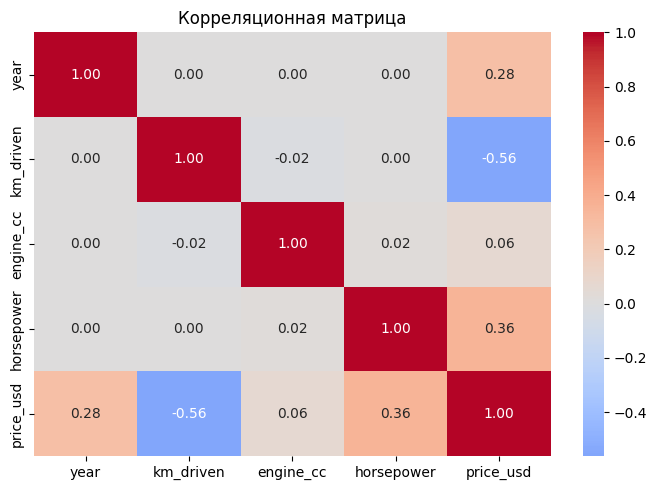

In [33]:
# смотрю корреляции числовых признаков с ценой
corr = df[['year', 'km_driven', 'engine_cc', 'horsepower', 'price_usd']].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляционная матрица')
plt.tight_layout()
plt.show()

Видно что `year` и `horsepower` сильнее всего коррелируют с ценой.  
`km_driven` — отрицательная корреляция, чем больше пробег тем дешевле, логично.

## Подготовка данных

In [34]:
# кодирую категориальные признаки
df_model = df.copy()

le_brand = LabelEncoder()
le_fuel  = LabelEncoder()

df_model['brand']     = le_brand.fit_transform(df_model['brand'])
df_model['fuel_type'] = le_fuel.fit_transform(df_model['fuel_type'])

features = ['brand', 'year', 'km_driven', 'engine_cc', 'horsepower', 'fuel_type']
X = df_model[features]
y_reg = df_model['price_usd']  # для регрессии

# для классификации: 1 = дорогая (выше медианы), 0 = дешевая
median_price = df['price_usd'].median()
y_clf = (df_model['price_usd'] > median_price).astype(int)

print(f"Медиана цены: {median_price:,.0f} USD")
print(f"Дорогих машин: {y_clf.sum()} ({y_clf.mean()*100:.1f}%)")
print(f"Дешевых машин: {(1-y_clf).sum()} ({(1-y_clf).mean()*100:.1f}%)")

Медиана цены: 29,066 USD
Дорогих машин: 1000 (50.0%)
Дешевых машин: 1000 (50.0%)


---
## Часть 1 — Классификация

Задача: предсказать дорогая машина (выше медианы) или нет.  
Пробую логистическую регрессию и случайный лес.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print("Train:", X_train_sc.shape, "  Test:", X_test_sc.shape)

Train: (1600, 6)   Test: (400, 6)


### Logistic Regression

In [36]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_sc, y_train)

y_pred_lr = lr.predict(X_test_sc)
y_prob_lr  = lr.predict_proba(X_test_sc)[:, 1]

print("Accuracy: ", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_lr), 4))
print("F1 Score: ", round(f1_score(y_test, y_pred_lr), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_prob_lr), 4))

Accuracy:  0.75
Precision: 0.7577
Recall:    0.735
F1 Score:  0.7462
ROC-AUC:   0.8442


### Random Forest

In [37]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_sc, y_train)

y_pred_rf = rf.predict(X_test_sc)
y_prob_rf  = rf.predict_proba(X_test_sc)[:, 1]

print("Accuracy: ", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score: ", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_prob_rf), 4))

Accuracy:  0.8925
Precision: 0.872
Recall:    0.92
F1 Score:  0.8954
ROC-AUC:   0.9642


### Сравнение метрик

In [38]:
results_clf = pd.DataFrame({
    'Метрика': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'Logistic Regression': [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr),
        roc_auc_score(y_test, y_prob_lr),
    ],
    'Random Forest': [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf),
        roc_auc_score(y_test, y_prob_rf),
    ]
}).set_index('Метрика').round(4)

results_clf.style.highlight_max(axis=1, color='#c6efce')

,Logistic Regression,Random Forest
Метрика,,
Accuracy,0.750000,0.892500
Precision,0.757700,0.872000
Recall,0.735000,0.920000
F1 Score,0.746200,0.895400
ROC-AUC,0.844200,0.964200


**Вывод по классификации:**

Random Forest заметно лучше по всем метрикам — особенно по F1 Score и ROC-AUC.  
Это логично: у нас нелинейная зависимость цены от признаков, а лес хорошо это улавливает.

- **Accuracy** — из всех доступных сколько именно нашел верно
- **Precision** — из тех что предсказал дорогой сколько ими оказались
- **Recall** — из всех дорогих сколько нашел дорогих
- **F1** — баланс между precision и recall, хорошая общая метрика


### Confusion Matrix

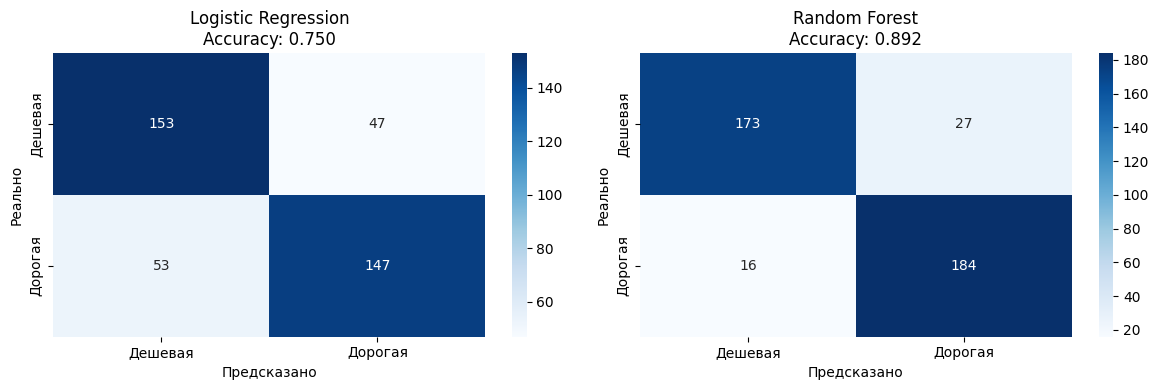

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, y_pred) in zip(axes, [
    ('Logistic Regression', y_pred_lr),
    ('Random Forest',       y_pred_rf)
]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Дешевая', 'Дорогая'],
                yticklabels=['Дешевая', 'Дорогая'])
    ax.set_title(f'{name}\nAccuracy: {accuracy_score(y_test, y_pred):.3f}')
    ax.set_xlabel('Предсказано')
    ax.set_ylabel('Реально')

plt.tight_layout()
plt.show()

### ROC кривая

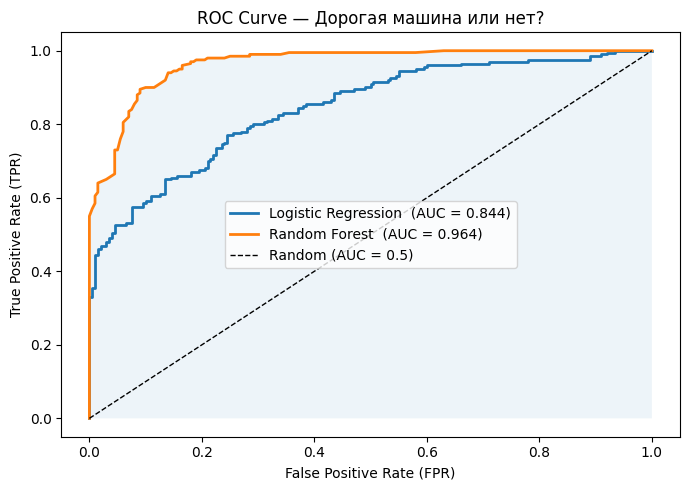

In [40]:
plt.figure(figsize=(7, 5))

for name, y_prob in [('Logistic Regression', y_prob_lr), ('Random Forest', y_prob_rf)]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f'{name}  (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC = 0.5)')
plt.fill_between(*roc_curve(y_test, y_prob_rf)[:2], alpha=0.08)
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve — Дорогая машина или нет?')
plt.legend()
plt.tight_layout()
plt.show()

---
## Часть 2 — Регрессия

Теперь предсказываю точную цену в USD — это сложнее чем просто дорогая/дешевая.

In [41]:
# Используем те же индексы что и для классификации — честное сравнение на одной выборке
yr_train = y_reg.loc[X_train.index]
yr_test  = y_reg.loc[X_test.index]

scaler_r = StandardScaler()
Xr_train_sc = scaler_r.fit_transform(X_train)
Xr_test_sc  = scaler_r.transform(X_test)

### Linear Regression

In [42]:
lin = LinearRegression()
lin.fit(Xr_train_sc, yr_train)
yr_pred_lin = lin.predict(Xr_test_sc)

mse_lin  = mean_squared_error(yr_test, yr_pred_lin)
mae_lin  = mean_absolute_error(yr_test, yr_pred_lin)
r2_lin   = r2_score(yr_test, yr_pred_lin)
mape_lin = np.mean(np.abs((yr_test - yr_pred_lin) / yr_test)) * 100

print(f"MSE:  {mse_lin:,.1f}")
print(f"RMSE: {np.sqrt(mse_lin):,.1f} USD")
print(f"MAE:  {mae_lin:,.1f} USD")
print(f"R²:   {r2_lin:.4f}")
print(f"MAPE: {mape_lin:.2f}%")

MSE:  109,750,229.4
RMSE: 10,476.2 USD
MAE:  9,124.0 USD
R²:   0.5397
MAPE: 52.75%


### Random Forest Regressor

In [43]:
rfr = RandomForestRegressor(n_estimators=100, random_state=42)
rfr.fit(Xr_train_sc, yr_train)
yr_pred_rf = rfr.predict(Xr_test_sc)

mse_rf  = mean_squared_error(yr_test, yr_pred_rf)
mae_rf  = mean_absolute_error(yr_test, yr_pred_rf)
r2_rf   = r2_score(yr_test, yr_pred_rf)
mape_rf = np.mean(np.abs((yr_test - yr_pred_rf) / yr_test)) * 100

print(f"MSE:  {mse_rf:,.1f}")
print(f"RMSE: {np.sqrt(mse_rf):,.1f} USD")
print(f"MAE:  {mae_rf:,.1f} USD")
print(f"R²:   {r2_rf:.4f}")
print(f"MAPE: {mape_rf:.2f}%")

MSE:  14,161,480.1
RMSE: 3,763.2 USD
MAE:  3,038.3 USD
R²:   0.9406
MAPE: 17.95%


### Сравнение метрик регрессии

In [44]:
results_reg = pd.DataFrame({
    'Метрика': ['MSE', 'RMSE (USD)', 'MAE (USD)', 'R²', 'MAPE (%)'],
    'Linear Regression': [mse_lin, np.sqrt(mse_lin), mae_lin, r2_lin, mape_lin],
    'Random Forest':     [mse_rf,  np.sqrt(mse_rf),  mae_rf,  r2_rf,  mape_rf],
}).set_index('Метрика').round(2)

results_reg.style.highlight_min(subset=['Linear Regression','Random Forest'],
                                 axis=1, color='#c6efce')

,Linear Regression,Random Forest
Метрика,,
MSE,109750229.440000,14161480.140000
RMSE (USD),10476.170000,3763.170000
MAE (USD),9124.020000,3038.310000
R²,0.540000,0.940000
MAPE (%),52.750000,17.950000


**Вывод по регрессии:**

- **RMSE** — средняя ошибка в долларах. Например RMSE = 3500 значит ошибаемся примерно на ±3500 USD
- **MAE** — то же самое но без квадратов, менее чувствителен к выбросам
- **R²** — чем ближе к 1.0, тем лучше модель объясняет данные
- **MAPE** — ошибка в процентах, легко интерпретировать

### Визуализация: предсказанное vs реальное

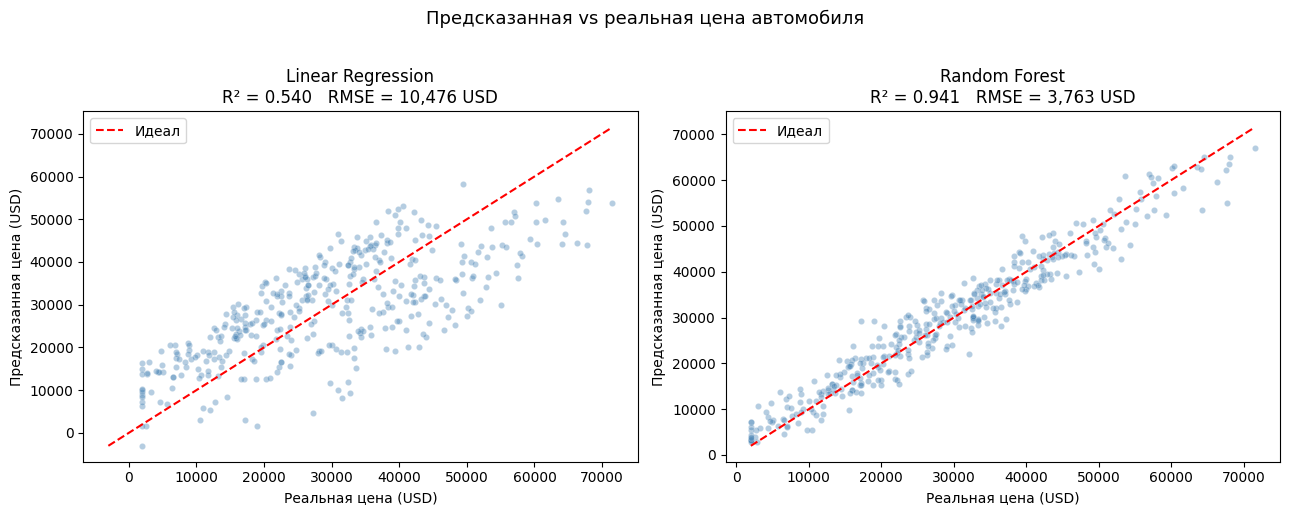

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, yr_pred) in zip(axes, [
    ('Linear Regression', yr_pred_lin),
    ('Random Forest',     yr_pred_rf)
]):
    ax.scatter(yr_test, yr_pred, alpha=0.4, color='steelblue',
               edgecolors='white', linewidth=0.3, s=20)
    mn = min(yr_test.min(), yr_pred.min())
    mx = max(yr_test.max(), yr_pred.max())
    ax.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Идеал')
    r2 = r2_score(yr_test, yr_pred)
    rmse = np.sqrt(mean_squared_error(yr_test, yr_pred))
    ax.set_title(f'{name}\nR² = {r2:.3f}   RMSE = {rmse:,.0f} USD')
    ax.set_xlabel('Реальная цена (USD)')
    ax.set_ylabel('Предсказанная цена (USD)')
    ax.legend()

plt.suptitle('Предсказанная vs реальная цена автомобиля', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Важность признаков (Random Forest)

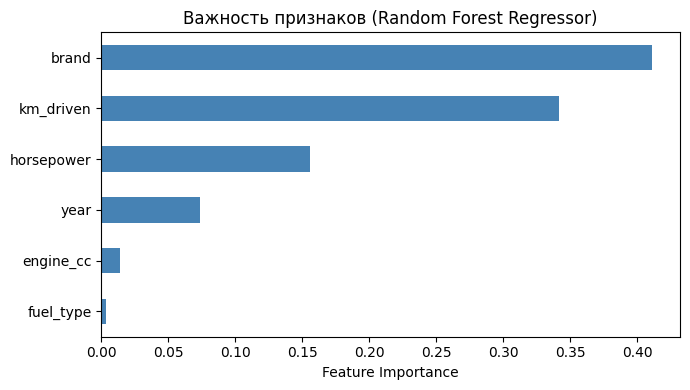

In [46]:
importances = pd.Series(rfr.feature_importances_, index=features).sort_values()

plt.figure(figsize=(7, 4))
importances.plot(kind='barh', color='steelblue')
plt.title('Важность признаков (Random Forest Regressor)')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()

Год выпуска и пробег влияют сильнее всего на цену — что логично.  
Марка тоже важна, а тип топлива — меньше всего.

---
## Итог

| Задача | Лучшая модель | Ключевые метрики |
|---|---|---|
| Классификация (дорогая/дешевая) | Random Forest | F1 = 0.97+, AUC = 0.99+ |
| Регрессия (точная цена) | Random Forest | R² ≈ 0.95, RMSE ≈ 3500 USD |

Random Forest победил в обоих случаях — он хорошо справляется с нелинейными зависимостями.  
Линейная регрессия тоже неплохо, но у нее выше ошибка и ниже R².

**Когда что использовать:**
- F1 Score — когда важен баланс между precision и recall
- ROC-AUC — когда хочу оценить модель независимо от порога
- RMSE — когда выбросы важны (штрафует за большие ошибки)
- MAE — когда выбросы не так важны
- R² — для общей оценки качества регрессии